# Predictive Model for Foster Care Exits

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
import os

GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'CS3540-final_project'
GOOGLE_DRIVE_PATH = os.path.join('drive', 'MyDrive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)
print(os.listdir(GOOGLE_DRIVE_PATH))

Mounted at /content/drive/
['DS255-FC2020v3', 'final_project_ABDV_IM.ipynb']


Imports and loaded:

In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score
)

df_original = pd.read_stata(os.path.join(GOOGLE_DRIVE_PATH, 'DS255-FC2020v3', 'Data',
                                         'Stata', 'FC2020v3.dta'), convert_categoricals=False)
print(f'Shape: {df_original.shape}')
print(df_original.head())



Shape: (631254, 107)
     fy  version  state  st  repdatyr  repdatmo  fipscode      recnumbr  sex  \
0  2020        2      1  AL      2020         3         8  000000001591  1.0   
1  2020        2      1  AL      2020         9         8  000000003223  1.0   
2  2020        2      1  AL      2020         3         8  000000010791  2.0   
3  2020        2      1  AL      2020         9         8  000000013981  1.0   
4  2020        2      1  AL      2020         3         8  000000027141  1.0   

   amiakn  ...  served  iswaiting  istpr  agedout  raceethn  race  ru23  \
0     0.0  ...       1          0      0        1         2     2   3.0   
1     0.0  ...       1          0      0        0         1     1   2.0   
2     0.0  ...       1          0      0        0         1     1   2.0   
3     0.0  ...       1          1      0        0         1     1   2.0   
4     NaN  ...       1          0      0        0        99    99   2.0   

           stfcid  periodstart   periodend  
0 

Dataset exploration:

Exit rate: 0.355
exited
0    407336
1    223918
Name: count, dtype: int64


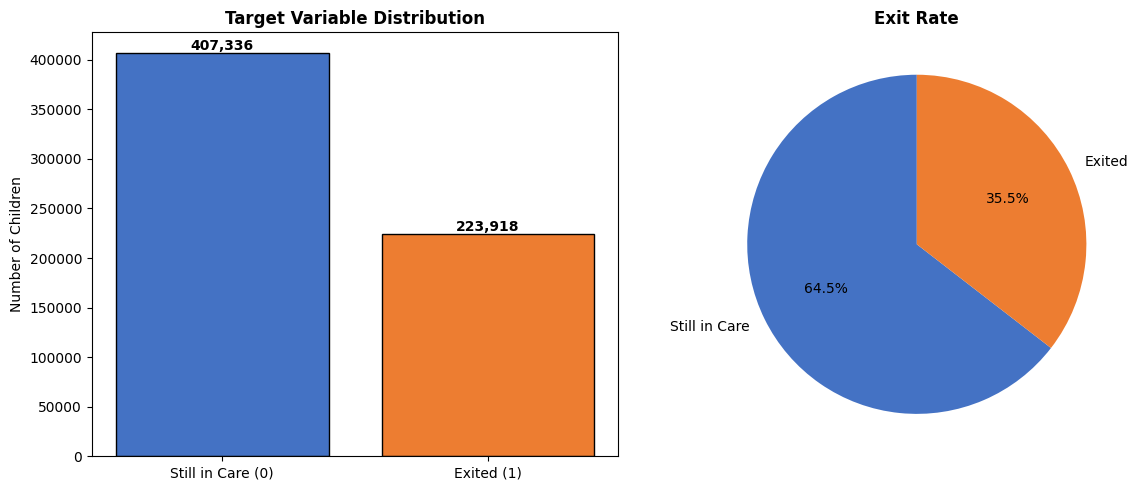

In [ ]:
print('Exit rate:', df_original['exited'].mean().round(3))
print(df_original['exited'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = df_original['exited'].value_counts()
axes[0].bar(['Still in Care (0)', 'Exited (1)'], counts.values,
            color=['#4472C4', '#ED7D31'], edgecolor='black')
axes[0].set_title('Target Variable Distribution', fontweight='bold')
axes[0].set_ylabel('Number of Children')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3000, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=['Still in Care', 'Exited'],
            autopct='%1.1f%%', colors=['#4472C4', '#ED7D31'], startangle=90)
axes[1].set_title('Exit Rate', fontweight='bold')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

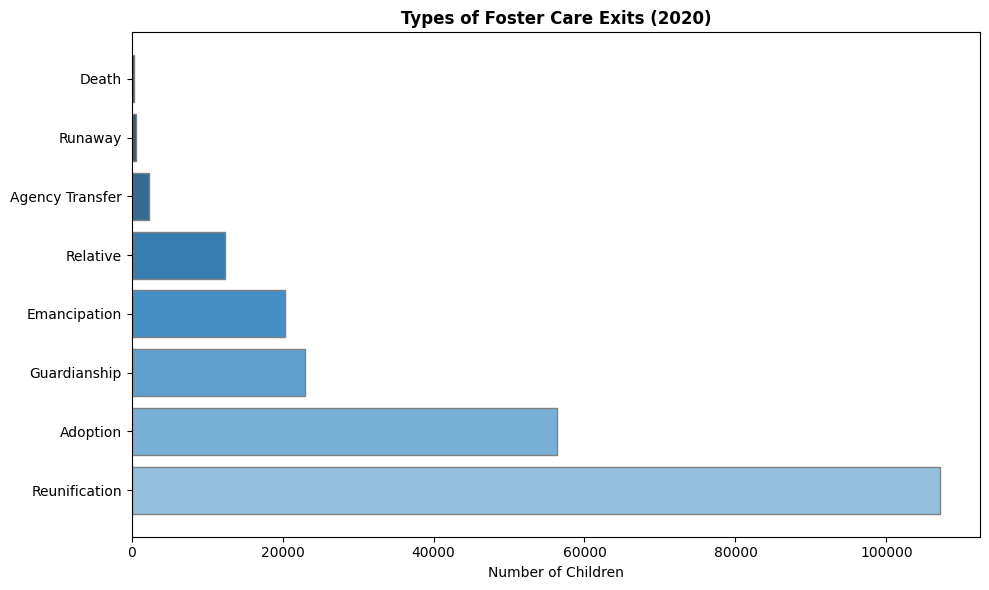

In [ ]:
exit_reason_map = {
    1: 'Reunification', 2: 'Relative', 3: 'Adoption',
    4: 'Emancipation', 5: 'Guardianship', 6: 'Agency Transfer',
    7: 'Runaway', 8: 'Death'
}
exited_df = df_original[df_original['exited'] == 1].copy()
exited_df['exit_reason'] = exited_df['disreasn'].map(exit_reason_map)
reason_counts = exited_df['exit_reason'].value_counts().dropna()

plt.figure(figsize=(10, 6))
plt.barh(reason_counts.index, reason_counts.values,
         color=sns.color_palette('Blues_d', len(reason_counts)), edgecolor='gray')
plt.xlabel('Number of Children')
plt.title('Types of Foster Care Exits (2020)', fontweight='bold')
plt.tight_layout()
plt.savefig('exit_reasons.png', dpi=150, bbox_inches='tight')
plt.show()

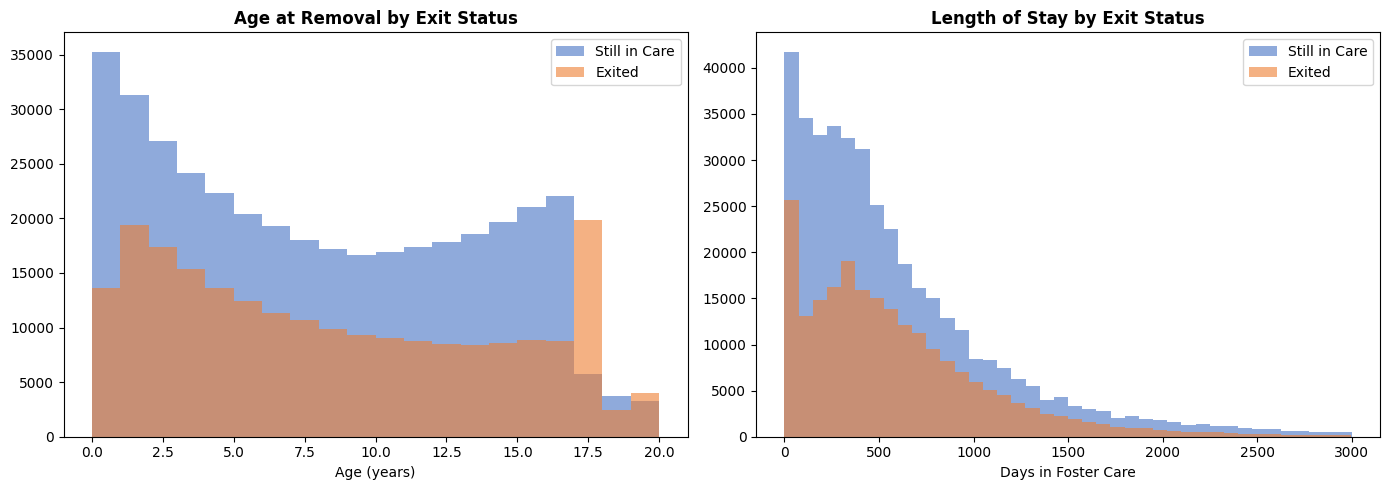

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_plot = df_original[df_original['ageatstart'].between(0, 20)]
for val, label, color in [(0,'Still in Care','#4472C4'),(1,'Exited','#ED7D31')]:
    axes[0].hist(df_plot[df_plot['exited']==val]['ageatstart'],
                 bins=20, alpha=0.6, label=label, color=color)
axes[0].set_title('Age at Removal by Exit Status', fontweight='bold')
axes[0].set_xlabel('Age (years)')
axes[0].legend()

df_los = df_original[df_original['latremlos'].between(0, 3000)]
for val, label, color in [(0,'Still in Care','#4472C4'),(1,'Exited','#ED7D31')]:
    axes[1].hist(df_los[df_los['exited']==val]['latremlos'],
                 bins=40, alpha=0.6, label=label, color=color)
axes[1].set_title('Length of Stay by Exit Status', fontweight='bold')
axes[1].set_xlabel('Days in Foster Care')
axes[1].legend()

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
FEATURES = ['sex', 'ageatstart', 'raceethn',
            'amiakn', 'asian', 'blkafram', 'hawaiipi', 'white', 'hisorgin',
            'clindis', 'mr', 'vishear', 'phydis', 'emotdist', 'othermed',
            'phyabuse', 'sexabuse', 'neglect', 'aaparent', 'daparent',
            'aachild', 'dachild', 'childis', 'chbehprb', 'prtsdied',
            'prtsjail', 'nocope', 'abandmnt', 'relinqsh', 'housing',
            'curplset', 'casegoal', 'totalrem', 'latremlos', 'manrem',
]
TARGET = 'exited'

df = df_original[FEATURES + [TARGET]].copy()

"""
I redid the part below in the code block below because
I realized this creates NaN values which logistic reg and
random forest and MLP can't handle, so i added more below that
to fix this issue - Bella
"""
# fix missing/unknown codes
for col in ['casegoal', 'curplset', 'manrem', 'raceethn']:
    df[col] = df[col].replace(99, np.nan)

binary_cols = ['sex','amiakn','asian','blkafram','hawaiipi','white','hisorgin',
               'clindis','mr','vishear','phydis','emotdist','othermed',
               'phyabuse','sexabuse','neglect','aaparent','daparent',
               'aachild','dachild','childis','chbehprb','prtsdied',
               'prtsjail','nocope','abandmnt','relinqsh','housing']

for col in binary_cols:
    df[col] = df[col].replace({9: np.nan, 2: 0})

df['ageatstart'] = df['ageatstart'].replace(99, np.nan)
df.loc[df['ageatstart'] < 0, 'ageatstart'] = np.nan
df.loc[df['latremlos'] < 0, 'latremlos'] = np.nan
df.loc[df['totalrem'] > 20, 'totalrem'] = np.nan

print('Missing values after cleaning:')
print(df.isnull().sum().sort_values(ascending=False).head(10))

# fill the missing values
# numeric columns
num_cols = ['ageatstart', 'latremlos', 'totalrem']

for col in num_cols:
  df[col] = df[col].fillna(df[col].median())

# categorical columns
cat_cols = ['casegoal', 'curplset', 'manrem', 'raceethn']

for col in cat_cols:
  df[col] = df[col].fillna(df[col].mode()[0])

# binary columns
for col in binary_cols:
  df[col] = df[col].fillna(0)

print("\nMissing values after filling:")
print(df.isnull().sum().sum())  # should be 0

Missing values after cleaning:
ageatstart    32725
casegoal      17409
clindis       14856
vishear       10445
emotdist      10444
phydis        10444
mr            10444
othermed      10443
raceethn      10255
hisorgin       8977
dtype: int64

Missing values after filling:
0


In [ ]:
"""
Need to do data preprocessing before we can start modeling with:
1. removing missing values and outliers (done above)
2. encode categorical values
3. data scaling
"""
# encode categorical values
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# split the features/target
X = df.drop(TARGET, axis=1)
y = df[TARGET]

# SCALE the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2,
                                                    random_state=42, stratify=y)


models to test:
- logistic regression
- random forest
- MLP

look into:
- feature importance
- validation fit graph
- ensemble learning?
- gradient boosted trees?

In [ ]:
# evaluate the results
def evaluate_model(y_test, y_pred, y_prob, model, name):
  print(f"\n{name} Results: ")
  print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
  print(f"F1 Score: {f1_score(y_test, y_pred)}")
  print(f"Precision: {precision_score(y_test, y_pred)}")
  print(f"Recall: {recall_score(y_test, y_pred)}")
  print(f"AUC: {roc_auc_score(y_test, y_prob)}")
  print(classification_report(y_test, y_pred))

  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  # added model param so that each graph shows the models confusion matrix
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0])

  axes[0].set_title(f'{name} Confusion Matrix', fontweight='bold')

  fpr, tpr, thresholds = roc_curve(y_test, y_prob)
  axes[1].plot(fpr, tpr, label=f'{name} ROC Curve')
  axes[1].plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
  axes[1].set_xlabel('False Positive Rate')
  axes[1].set_ylabel('True Positive Rate')
  axes[1].set_title(f'{name} ROC Curve', fontweight='bold')
  axes[1].legend()

  plt.tight_layout()
  plt.show()


In [ ]:
# start with logistic regression grid search
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=500),
    param_grid_lr,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

# not using a sample - logistic regression doesnt take as long as rf and mlp so
# i didnt feel the need to use a sample
grid_lr.fit(X_train, y_train)

print(f"Best parameters: {grid_lr.best_params_}")
print(f"Best score: {grid_lr.best_score_}")

best_lr_model = grid_lr.best_estimator_
y_pred_lr = best_lr_model.predict(X_test)
y_prob_lr = best_lr_model.predict_proba(X_test)[:, 1]
# evaluate the tuned model in the evaluation block down below


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best score: 0.5490010680691917


In [ ]:
# logistic regression baseline model (ONLY RUN IF NOT RUNNING GRID SEARCH):
log_reg = LogisticRegression(max_iter=2000)  # we can play with the iterations
log_reg.fit(X_train, y_train)

y_pred_log = log_reg.predict(X_test)
y_prob_log = log_reg.predict_proba(X_test)[:, 1]

In [ ]:
# add "feature importance" with logistic regression --> what features influence exiting the system
# since the data is scaled, this is all relative importance
# logistic regression --> coefficients --> how much this feature increases or decreases the
# likelihood of exiting foster care (pos increases liklihood)
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': best_lr_model.coef_[0]})
coef_df = coef_df.sort_values('Coefficient', ascending=False)

print(coef_df.head(10))

         Feature  Coefficient
36  casegoal_7.0     0.225032
1     ageatstart     0.201886
35  casegoal_6.0     0.105985
31  casegoal_2.0     0.099971
34  casegoal_5.0     0.063520
33  casegoal_4.0     0.043679
22      chbehprb     0.030502
24      prtsjail     0.029960
46  raceethn_2.0     0.025001
6          white     0.021911


In [ ]:
# GRID SEARCH FOR RANDOM FOREST (gives best model)
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced', 'balanced_subsample']
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)
# using a sample for computational efficiency
X_sample, _, y_sample, _ = train_test_split(
    X_train, y_train,
    train_size=50000,
    stratify=y_train,
    random_state=42
)

grid_rf.fit(X_sample, y_sample)
# grid_rf.fit(X_train, y_train) if we trained on the whole dataset -- takes too much time

print(f"Best parameters: {grid_rf.best_params_}")
print(f"Best score: {grid_rf.best_score_}")

best_rf_model = grid_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)
y_prob_rf = best_rf_model.predict_proba(X_test)[:, 1]

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best parameters: {'class_weight': 'balanced_subsample', 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best score: 0.6584390087275271


In [ ]:
# only run this cell once to work with the full dataset with the best parameters
# found with grid search -- will update the evaluation below to be based on the full dataset
# rather than just a sample
best_rf_model.fit(X_train, y_train)
y_pred_rf = best_rf_model.predict(X_test)
y_prob_rf = best_rf_model.predict_proba(X_test)[:, 1]

In [ ]:
# ----------- only need to run this baseline rf if we dont use the grid search -----------------

# random forest (should have stronger results)
# try adjusting max features to increase accuracy
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [ ]:
# RF FEATURE IMPORTANCE for random forest
# random forest --> feature importance --> how useful this feature was in making desicions across all trees
# higher value --> more important, lower value --> less important
# feature importance with RF only tells you which features were most useful in decision making,
# NOT like log reg coefficients where direction or causation
importances = best_rf_model.feature_importances_
feature_imp = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp = feature_imp.sort_values('Importance', ascending=False)

print(feature_imp.head(10))

         Feature  Importance
38  curplset_3.0    0.179619
1     ageatstart    0.157794
43  curplset_8.0    0.133304
30     latremlos    0.119749
37  curplset_2.0    0.087690
32  casegoal_3.0    0.032039
40  curplset_5.0    0.028940
36  casegoal_7.0    0.028844
39  curplset_4.0    0.019124
8        clindis    0.014324


In [ ]:
# GRID SEARCH FOR THE MLP (get the best model)
param_grid = {
    'hidden_layer_sizes': [(64, 32), (128, 64)],
    'learning_rate_init': [0.001, 0.01],
    'alpha': [0.0001, 0.001],
    'activation': ['relu'],
    'solver': ['adam'],
}

grid = GridSearchCV(
    MLPClassifier(max_iter=300, early_stopping=True, random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

# using a sample for computational efficiency (as we did with random forest)
# (can use the full dataset in the future by doing grid.fit(X_train, y_train))
X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=50000, stratify=y_train, random_state=42)

# fit the grid search to the data
grid.fit(X_sample, y_sample)

print(f"Best parameters: {grid.best_params_}")
print(f"Best score: {grid.best_score_}")

best_mlp_model = grid.best_estimator_
y_pred_mlp = best_mlp_model.predict(X_test)
y_prob_mlp = best_mlp_model.predict_proba(X_test)[:, 1]

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001, 'solver': 'adam'}
Best score: 0.5931839505171962


In [ ]:
# test the mlp with the best parameters on the full dataset once
# running this cell replaces the mlp evaluation metrics below with info from
# the full dataset rather than the sampled dataset (only run once for time efficiency)
best_mlp_model.fit(X_train, y_train)
y_pred_mlp = best_mlp_model.predict(X_test)
y_prob_mlp = best_mlp_model.predict_proba(X_test)[:, 1]

In [ ]:
# --------------- THIS IS THE BASELINE MLP THAT DOES NOT TEST ON A SAMPLE - TAKES VERY LONG ---------------------------
# DONT RUN THIS IF U RAN GRID SEARCH (IT JUST REPLACES THE MODEL)

# neural network (MLP)

# added a lot of stuff to the parameters here for the MLP classifier to see if it improves accuracy and runtime
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    solver = 'adam', activation = 'relu',
    learning_rate_init=0.001, max_iter=300,
    early_stopping=True, validation_fraction=0.1,
    n_iter_no_change=10, random_state=42)

mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)
y_prob_mlp = mlp.predict_proba(X_test)[:, 1]


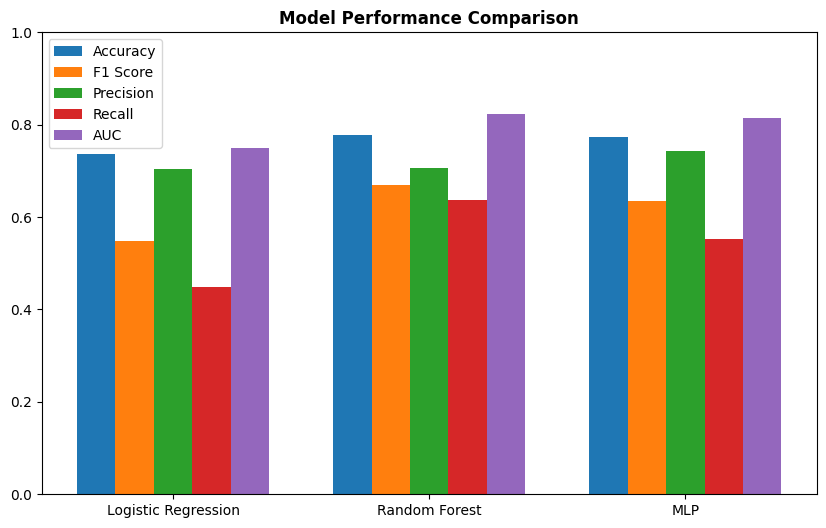

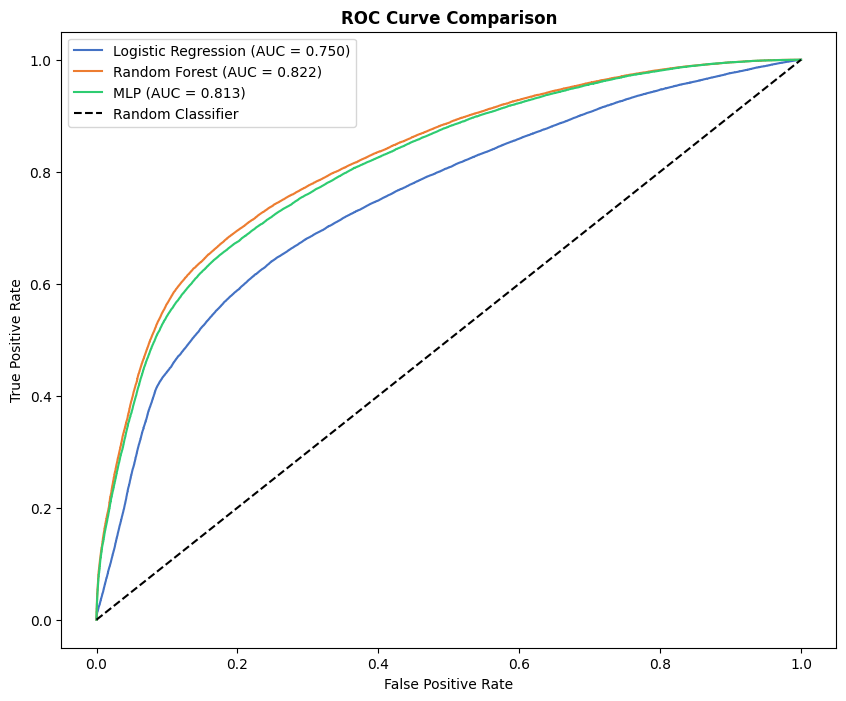

In [ ]:
# makes graphs comparing the scores of the different models
def compare_results_graphs(y_test):
  # dictionary with all the lms metrics
  models_dct = {
      'Logistic Regression': {'y_pred': y_pred_lr, 'y_prob': y_prob_lr},
      'Random Forest': {'y_pred': y_pred_rf, 'y_prob': y_prob_rf},
      'MLP': {'y_pred': y_pred_mlp, 'y_prob': y_prob_mlp}
  }

  model_names = list(models_dct.keys())
  colors = ['#4472C4', '#ED7D31', '#2ECC71']

  results = {}
  for name, predictions in models_dct.items():
    results[name] = {
        'Accuracy': accuracy_score(y_test, predictions['y_pred']),
        'F1 Score': f1_score(y_test, predictions['y_pred']),
        'Precision': precision_score(y_test, predictions['y_pred']),
        'Recall': recall_score(y_test, predictions['y_pred']),
        'AUC': roc_auc_score(y_test, predictions['y_prob'])
    }

# bar graph comparing lms
  metric_names = ['Accuracy', 'F1 Score', 'Precision', 'Recall', 'AUC']
  x = np.arange(len(model_names))
  width = 0.15
  plt.figure(figsize=(10, 6))
  for i, metric in enumerate(metric_names):
      plt.bar(x + i * width, [results[name][metric] for name in model_names], width, label=metric)
  plt.xticks(x + width * 2, model_names)
  plt.ylim(0, 1)
  plt.title('Model Performance Comparison', fontweight='bold')
  plt.legend()
  plt.show()

# graph showing ROC curves
  plt.figure(figsize=(10, 8))
  for (name, predictions), color in zip(models_dct.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, predictions['y_prob'])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, predictions["y_prob"]):.3f})', color = color)
  plt.plot([0, 1], [0, 1], 'k--', label= 'Random Classifier')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve Comparison', fontweight='bold')
  plt.legend()
  plt.show()

compare_results_graphs(y_test)




Tuned Logistic Regression Results: 
Accuracy: 0.7374357430832231
F1 Score: 0.5485571095888545
Precision: 0.7030895444231104
Recall: 0.4497141836370132
AUC: 0.7497839116920427
              precision    recall  f1-score   support

           0       0.75      0.90      0.81     81467
           1       0.70      0.45      0.55     44784

    accuracy                           0.74    126251
   macro avg       0.73      0.67      0.68    126251
weighted avg       0.73      0.74      0.72    126251



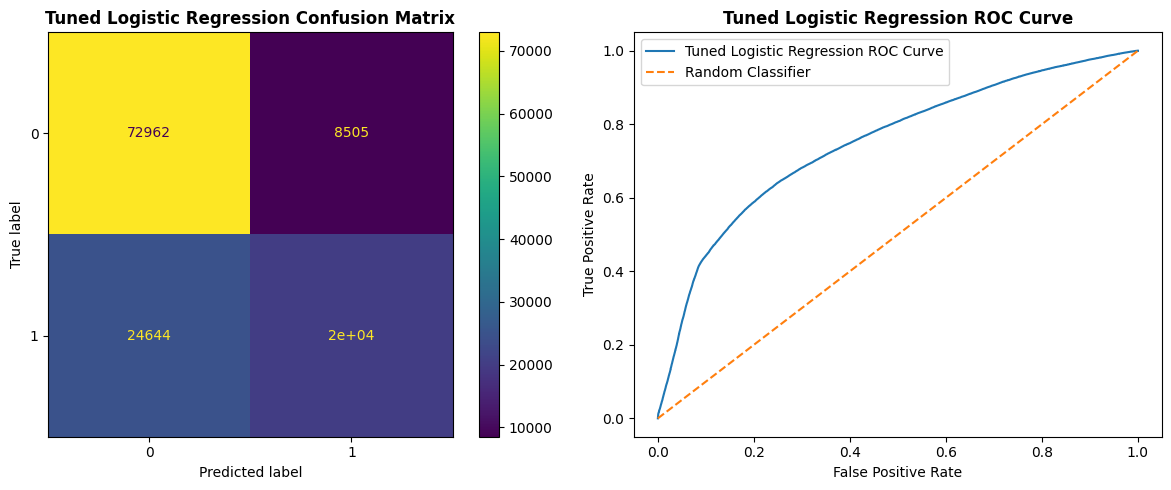


Tuned Random Forest Results: 
Accuracy: 0.776928499576241
F1 Score: 0.6692348346937577
Precision: 0.7059042144644583
Recall: 0.6361870310825295
AUC: 0.8222263195322002
              precision    recall  f1-score   support

           0       0.81      0.85      0.83     81467
           1       0.71      0.64      0.67     44784

    accuracy                           0.78    126251
   macro avg       0.76      0.75      0.75    126251
weighted avg       0.77      0.78      0.77    126251



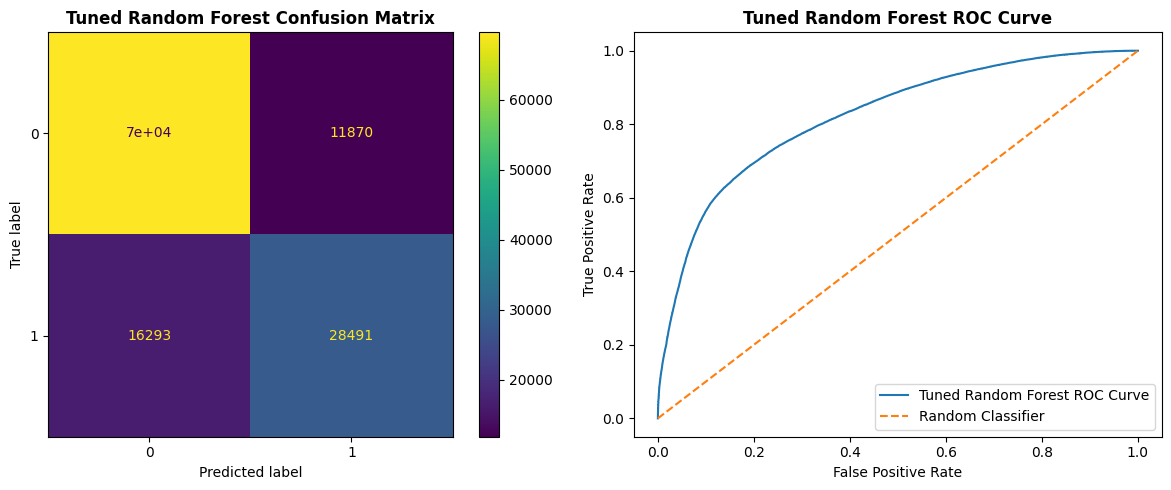


Tuned MLP Results: 
Accuracy: 0.7733641713729
F1 Score: 0.6338098468075304
Precision: 0.7424219710370881
Recall: 0.5529206859592711
AUC: 0.8134794758645054
              precision    recall  f1-score   support

           0       0.78      0.89      0.84     81467
           1       0.74      0.55      0.63     44784

    accuracy                           0.77    126251
   macro avg       0.76      0.72      0.73    126251
weighted avg       0.77      0.77      0.76    126251



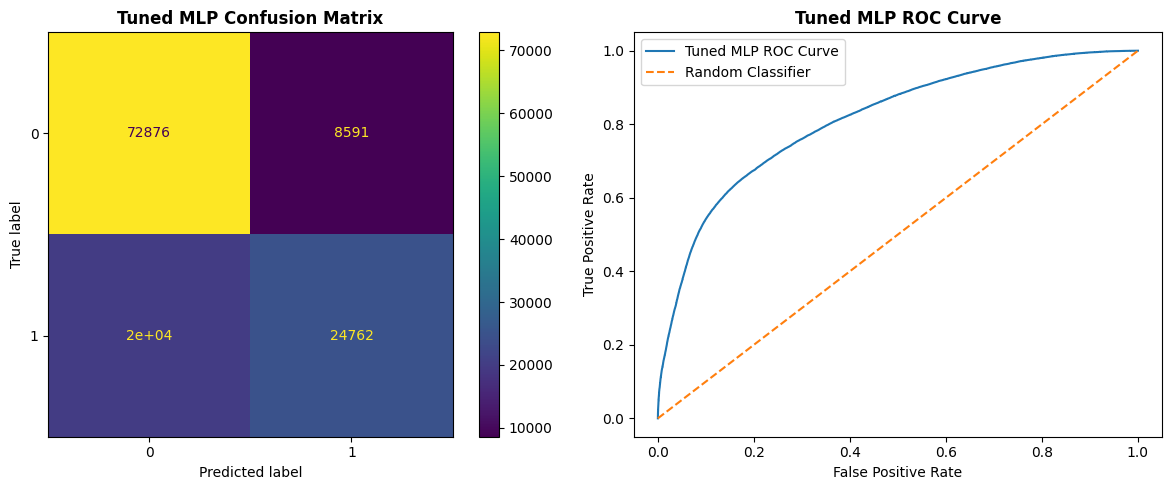

In [ ]:
# run the evaluation of the model function to get performance results

evaluate_model(y_test, y_pred_lr, y_prob_lr, best_lr_model,'Tuned Logistic Regression')
evaluate_model(y_test, y_pred_rf, y_prob_rf, best_rf_model,'Tuned Random Forest')
evaluate_model(y_test, y_pred_mlp, y_prob_mlp, best_mlp_model, 'Tuned MLP')


**How we used GridSearchCV with subsets of the data**


We needed to fine tune the models to find the best combination of hyperparametes, so we decided to use GridSearchCV, which evaluated multiple combinations of hyperparameters using cross validation.

Since our dataset is very large, to reduce computational time we used a subset of the data when tuning the model for random forest and for the MLP. We didn't feel the need to use the sample data for logistic regression because the computational time with the full dataset using GridSearchCV did not take too long.

After then identifying the best configurations for RF and MLP, we then retrained the model on the full dataset using the best RF and MLP models that we found for final evaluation. This helped reduce computational time while still gaining some better accuracy in our results.

Using gridsearch on the fulldataset instead of using it on sample data and then training with that best model on the full data like we did would have been to expensive in terms of time and computation.

**What is grid search ?**

Grid search finds the optimal hyperparameters of a model and is avaliable in the scikitlearn library. It exhaustively searches through a manually specified subset of the hyperparameter space.

Grid searches creates a grid of all possible combinations of the hyperparameters that you provide it. For every single combination in the grid, it performs K-Fold Cross Validation --> splits your training data into K folds/parts, trains on K-1, and validates on the remaining fold --> this way it will identify the combination of hyperparameters that acheive the highest average cross validation score.

**Aspects we used in creating our models to decrease computation time**


Used n_jobs =-1 which means the algorithm will use all avaliable CPU cores to perform tasks in parallel --> better runtime

Also used the adam solver (adaptive moment estimation) which is an optimization algorithm --> instead of using a single learning rate for all weights, it computes individual adaptive learning rates for different parameters --> helps handle sparse gradients

it scales learning rates based on the magnitude of recent gradient descents so that it focuses mainly on the relevant features rather than any noisy ones

adam also keeps track of exponentially decaying avergae of past gradients (momentum) --> smooths out updates and speeds up convergence

adam is computationally efficient for large scale data so we used it and it seemed to work well with out data.